# Lab 3 — Millions of TVs, Who Is Watching?
Name: Yeromenko Marharyta | Group: KM-42

## Setup

In [1]:
import kagglehub
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import re
DATA = kagglehub.dataset_download("shkarupylomaxim/adtech-lab1-tv-panel/versions/4")
programs = pd.read_parquet(f"{DATA}/programs.parquet")
viewings = pd.read_parquet(f"{DATA}/viewings.parquet")
daily_weights = pd.read_parquet(f"{DATA}/daily_weights.parquet")
viewer_attributes = pd.read_parquet(f"{DATA}/viewer_attributes.parquet")
attributes = pd.read_parquet(f"{DATA}/attributes.parquet")
acr_sessions = pd.read_parquet(f"{DATA}/acr_sessions.parquet")
hh_attributes = pd.read_parquet(f"{DATA}/hh_attributes.parquet")
reference_ratings = pd.read_parquet(f"{DATA}/reference_ratings.parquet")

In [2]:
first_day = pd.Timestamp('2024-10-14')
last_day = pd.Timestamp('2024-10-27')
ten_nets = sorted(programs['network_code'].unique())
big5 = ['CBS', 'NBC', 'ABC', 'FOX', 'FNC']

# dates as plain midnight timestamps everywhere (daily_weights keeps them as dates)
prog = programs.copy()
prog['broadcast_date'] = pd.to_datetime(prog['broadcast_date'])
dw = daily_weights.copy()
dw['broadcast_date'] = pd.to_datetime(dw['broadcast_date'])
# panel weights only for the same two weeks
dw2 = dw[(dw['broadcast_date'] >= first_day) & (dw['broadcast_date'] <= last_day)]

# ACR sessions: UTC -> US Eastern first (utc=True works with or without a time zone in the column)
acr = acr_sessions.copy()
acr['start_et'] = pd.to_datetime(acr['start_utc'], utc=True).dt.tz_convert('America/New_York').dt.tz_localize(None)
acr['end_et'] = pd.to_datetime(acr['end_utc'], utc=True).dt.tz_convert('America/New_York').dt.tz_localize(None)
acr['dur_min'] = (acr['end_et'] - acr['start_et']).dt.total_seconds() / 60
# broadcast day starts at 06:00, so shift 6 hours back and take the date
acr['bc_date'] = (acr['start_et'] - pd.Timedelta(hours=6)).dt.normalize()

# edit rule: drop sessions shorter than 1 minute
acr_ed = acr[acr['dur_min'] >= 1].copy()

# in-tab TVs: at least one session (any type) after the edit rule
tv_days = acr_ed.groupby('bc_date')['tv_id'].nunique()
n_tv_days = tv_days.sum()

# panel sessions with their broadcast day (needed in Task 3 and in the bonus)
v = viewings.copy()
v['bc_date'] = (v['start_ts'] - pd.Timedelta(hours=6)).dt.normalize()

print("Broadcast days in the ACR file:", acr['bc_date'].min().strftime('%Y-%m-%d'), "to", acr['bc_date'].max().strftime('%Y-%m-%d'))

Broadcast days in the ACR file: 2024-10-14 to 2024-10-27


## Task 1.1 — Five questions
**Answer:** 
| | `acr_sessions` (smart-TV ACR) | Lab 1 `viewings` (people-meter panel) |
|---|---|---|
| **Grain** | one session on one TV (live, DVR, app, unknown), any network | one session of one respondent (H, R/L, S), ten networks, live only |
| **Key** | `session_id`; `tv_id` = one household; `hashed_ip` links to the household file | `viewing_id`; `respondent_id` (household number x 100 + two digits) |
| **Coverage** | 29,940 opted-in TVs of one vendor, many DMAs, Oct 14-27; one set per home, no people | about 4,250 households and 10,200 persons in-tab; all sets and every person |
| **Weight** | none; every TV counts once | daily weights, projected to 125.8M households and 317M persons |
| **Provenance** | ACR fingerprint match; opt-in TVs; household facts from a consumer file by hashed IP | recruited homes with people meters; viewers press buttons; demographics measured |

The biggest difference is **weight** (and the representativeness behind it). The ACR feed is much bigger, but nobody chose which homes are in it, and nothing fixes who is missing. The panel is small, but it is weighted back to the country every day.

## Task 1.2 — Size and shape

In [3]:
raw_hours = acr['dur_min'].sum() / 60
ed_hours = acr_ed['dur_min'].sum() / 60

print("TVs:", acr_sessions['tv_id'].nunique())
print("Sessions:", len(acr_sessions))
print("Broadcast days:", acr['bc_date'].nunique())
print("Average TVs in-tab per day:", round(tv_days.mean()))
# both use the same denominator: in-tab TV-days (in-tab is defined after the edit rule)
print(f"Hours per TV per day, raw: {raw_hours / n_tv_days:.2f}")
print(f"Hours per TV per day, after edit rule: {ed_hours / n_tv_days:.2f}")
print(f"Share of sessions dropped: {1 - len(acr_ed) / len(acr):.3f}")

TVs: 29940
Sessions: 6392981
Broadcast days: 14
Average TVs in-tab per day: 29074
Hours per TV per day, raw: 4.74
Hours per TV per day, after edit rule: 4.70
Share of sessions dropped: 0.299


**Answer:** The edit rule drops 29.9% of all sessions, but only about 1% of the hours (4.74 → 4.70 hours per in-tab TV per day, about 16 thousand hours in total). The dropped sessions are therefore very short, well under a minute on average. This is what channel surfing looks like: many quick stops on the way to something else, almost no actual viewing. The rule cleans up the session count a lot, but it hardly changes the viewing time.

## Task 1.3 — What the TV could not see

In [4]:
acr_ed['hours'] = acr_ed['dur_min'] / 60
total_h = acr_ed['hours'].sum()

by_type = acr_ed.groupby('session_type')['hours'].sum() / total_h
by_input = acr_ed.groupby('input_source', dropna=False)['hours'].sum() / total_h

# table: share of hours by session_type and by input_source
display(by_type.round(3).sort_values(ascending=False).to_frame('share_of_hours'))
display(by_input.round(3).sort_values(ascending=False).to_frame('share_of_hours'))

print("Share of TV-on hours unknown (%):", round(by_type.get('unknown', 0) * 100, 1))

,share_of_hours
session_type,
unknown,0.396
live,0.322
app,0.257
dvr,0.025


,share_of_hours
input_source,
built_in_app,0.307
cable_box,0.276
streaming_device,0.231
antenna,0.086
satellite_box,0.076
game_or_disc,0.024


Share of TV-on hours unknown (%): 39.6


In [5]:
display(pd.crosstab(acr_ed['input_source'], acr_ed['session_type'], values=acr_ed['hours'], aggfunc='sum', normalize='all').round(3))

session_type,app,dvr,live,unknown
input_source,,,,
antenna,0.000,0.000,0.055,0.031
built_in_app,0.257,0.003,0.027,0.020
cable_box,0.000,0.015,0.170,0.091
game_or_disc,0.000,0.000,0.000,0.024
satellite_box,0.000,0.004,0.047,0.025
streaming_device,0.000,0.003,0.023,0.205


**Answer:** Unknown is 39.6% of the TV-on hours (live is 32.2%, app 25.7% and DVR 2.5%). A real feed can have even more, like the 66% in LG’s sample, for two reasons. First, ACR can only recognize what its fingerprint library contains: the live feeds of the networks and stations it has been built for. Anything outside it stays unknown, for example small local stations, regional channels, local ad breaks and other content with no reference feed. Matching can also fail for technical reasons, such as a weak signal or a delay. Second, a real home sends more of its viewing through sources that have no live feed to match, such as streaming devices, game consoles and disc players.

Two kinds of viewing that end up as unknown: (1) viewing on a streaming device (Roku, Fire TV and similar); (2) a game console or a disc player. The first one is the biggest part here. It is 0.205 of all hours, about half of the unknown, and about 89% of the hours from streaming devices are unknown, because the fingerprint has no live feed to match with. The second one is small in this file. All its hours are unknown, but game_or_disc is only 2.4% of all hours (about 6% of the unknown), so it cannot explain the 39.6%. Cable, antenna and satellite boxes give another 0.147 of unknown hours (about 37% of the unknown). This may be real live viewing that the library missed, for example a small local channel, but the table does not show which channels, so this is only a likely reason. DVR and app viewing have their own session types here, so they are not part of the unknown.

## Task 2.1 — Match


In [6]:
# one hashed_ip per TV (check first)
print("Max IPs per TV:", acr.groupby('tv_id')['hashed_ip'].nunique().max())
tvs = acr.groupby('tv_id')['hashed_ip'].first().to_frame()

# how many different households sit behind each IP in the household file
hh_per_ip = hh_attributes.groupby('hashed_ip')['household_id'].nunique()
tvs['n_hh'] = tvs['hashed_ip'].map(hh_per_ip).fillna(0).astype(int)

print("Matched to one household (%):", round((tvs['n_hh'] == 1).mean() * 100, 1))
print("Shared IP, unresolved (%):", round((tvs['n_hh'] > 1).mean() * 100, 1))
print("Not matched (%):", round((tvs['n_hh'] == 0).mean() * 100, 1))

Max IPs per TV: 1
Matched to one household (%): 65.2
Shared IP, unresolved (%): 11.8
Not matched (%): 22.9


**Answer:** In this dataset 65.2% of TVs match exactly one household, 11.8% share an IP with several households and 22.9% do not match at all, so only about two thirds of the TVs can be profiled. An IP address is a weak key because it is an internet connection, not a household. Several households can sit behind one IP (apartment buildings, shared routers), so we cannot tell whose TV it is, and we have to drop it. One household can also have more than one IP, or change it over time. The TV feed and the household file see the address at different times, so some real homes are not found. Even a correct match gives only household facts, many of them modeled, and not who is watching the TV.

## Task 2.2 — Profile

In [7]:
# households that matched exactly one household
one_ips = hh_per_ip[hh_per_ip == 1].index
hh_one = hh_attributes[hh_attributes['hashed_ip'].isin(one_ips)].drop_duplicates('hashed_ip')
matched = tvs[tvs['n_hh'] == 1].reset_index().merge(hh_one, on='hashed_ip', how='left')

def income_group(band):
    # 'Under $25k' -> 0, '$50k-$75k' -> 50, '$150k+' -> 150 (lower edge of the band, in $k)
    b = str(band)
    m = re.search(r'\d+', b)
    if m is None:
        return None
    low = 0 if b.lower().startswith('under') else int(m.group(0))
    if low < 50:
        return 'Under $50k'
    if low < 100:
        return '$50-100k'
    return '$100k+'

def region_name(s):
    s = str(s).lower()
    if 'northeast' in s:
        return 'Northeast'
    if 'midwest' in s or 'north central' in s:
        return 'Midwest'
    if 'south' in s:
        return 'South'
    if 'west' in s:
        return 'West'
    return None

matched['income_group'] = matched['income_band'].map(income_group)
matched['region_name'] = matched['region'].map(region_name)
print("income_band values in the household file:", sorted(hh_attributes['income_band'].dropna().unique()))

# the panel as the yardstick: H records, average weight over their in-tab days in Oct 14-27
hh_w = dw2[dw2['resp_type'] == 'H'].groupby('respondent_id')['weight'].mean()
pa = viewer_attributes.merge(attributes, on='attr_id')
pa = pa[pa['respondent_id'].isin(hh_w.index)]
reg_p = pa[pa['attr_group'].str.contains('region', case=False)].drop_duplicates('respondent_id').set_index('respondent_id')['attr_name']
inc_p = pa[pa['attr_group'].str.contains('income', case=False)].drop_duplicates('respondent_id').set_index('respondent_id')['attr_name']

panel_h = pd.DataFrame({'w': hh_w})
panel_h['region_name'] = reg_p.reindex(panel_h.index).map(region_name)
panel_h['income_group'] = inc_p.reindex(panel_h.index).map(income_group)
print("Panel households without region / income:", panel_h['region_name'].isna().sum(), "/", panel_h['income_group'].isna().sum())

rows = []
for col, order in [('region_name', ['Northeast', 'Midwest', 'South', 'West']),
                   ('income_group', ['Under $50k', '$50-100k', '$100k+'])]:
    foot = matched[col].value_counts(normalize=True)
    pan = panel_h.groupby(col)['w'].sum() / panel_h['w'].sum()
    for g in order:
        rows.append({'group': g, 'footprint_share': foot.get(g, 0), 'panel_share': pan.get(g, 0)})

profile = pd.DataFrame(rows)
profile['index'] = profile['footprint_share'] / profile['panel_share'] * 100
profile['footprint_share'] = profile['footprint_share'].round(3)
profile['panel_share'] = profile['panel_share'].round(3)
profile['index'] = profile['index'].round(1)

# table: group, footprint share, panel share, index (region and income)
display(profile)

# the household file also has the age of the head: footprint only (the panel table above has no head age)
print("Head of household age in the footprint:")
display(matched['head_age_band'].value_counts(normalize=True).sort_index().round(3).to_frame('footprint_share'))

income_band values in the household file: ['$100k-$150k', '$150k+', '$25k-$50k', '$50k-$75k', '$75k-$100k', 'Under $25k']
Panel households without region / income: 0 / 0


,group,footprint_share,panel_share,index
0,Northeast,0.150,0.170,88.0
1,Midwest,0.201,0.210,96.0
2,South,0.383,0.379,101.0
3,West,0.266,0.241,110.4
4,Under $50k,0.259,0.361,71.8
5,$50-100k,0.320,0.289,110.8
6,$100k+,0.421,0.350,120.1


Head of household age in the footprint:


,footprint_share
head_age_band,
18-34,0.196
35-49,0.348
50-64,0.263
65+,0.192


**Answer:** Over-represented: the West (index 110.4) and the higher-income homes, 100k+ (120.1) and 50-100k (110.8). Under-represented: the lowest income group, under 50k (71.8), and the Northeast (88.0). The South (101.0) and the Midwest (96.0) are close to the panel. So the footprint is richer than the country and a bit tilted to the West. One possible reason: people in an opted-in smart-TV footprint bought a newer smart TV of one brand and agreed to the tracking when they set it up. This is more common in higher-income homes, which replace TVs more often. Lower-income homes keep older sets or other brands.

In [8]:
# head of household in the panel: the person with code 701 (Household role = Head of house)
heads = viewer_attributes[viewer_attributes['attr_id'] == 701][['respondent_id']].drop_duplicates()
heads['hh_num'] = heads['respondent_id'] // 100
heads = heads.drop_duplicates('hh_num')

# exact age of each person (code 300)
age_exact = viewer_attributes[viewer_attributes['attr_id'] == 300].drop_duplicates('respondent_id').set_index('respondent_id')['value']
heads['age'] = heads['respondent_id'].map(age_exact)

# panel households with their weight (H records, average weight over Oct 14-27, from Task 2.2)
panel_hh = pd.DataFrame({'w': hh_w})
panel_hh['hh_num'] = panel_hh.index // 100
panel_hh = panel_hh.merge(heads[['hh_num', 'age']], on='hh_num', how='left')
print("Panel households without a head age:", panel_hh['age'].isna().sum())

# same age bands as the household file
labels = ['18-34', '35-49', '50-64', '65+']
panel_hh['head_age_band'] = pd.cut(panel_hh['age'], bins=[0, 35, 50, 65, 200], labels=labels, right=False)

pan_age = panel_hh.groupby('head_age_band', observed=True)['w'].sum()
pan_age = pan_age / pan_age.sum()
foot_age = matched['head_age_band'].value_counts(normalize=True)

age_profile = pd.DataFrame({'group': labels,
                            'footprint_share': [foot_age.get(l, 0) for l in labels],
                            'panel_share': [pan_age.get(l, 0) for l in labels]})
age_profile['index'] = (age_profile['footprint_share'] / age_profile['panel_share'] * 100).round(1)
age_profile['footprint_share'] = age_profile['footprint_share'].round(3)
age_profile['panel_share'] = age_profile['panel_share'].round(3)

# table: age of the head of household, footprint share, panel share, index
display(age_profile)

Panel households without a head age: 0


,group,footprint_share,panel_share,index
0,18-34,0.196,0.190,103.6
1,35-49,0.348,0.303,115.0
2,50-64,0.263,0.240,109.6
3,65+,0.192,0.267,71.8


## Task 2.3 — Ratings

In [9]:
ref = reference_ratings.merge(
    prog[['telecast_id', 'network_code', 'program_name', 'broadcast_date', 'start_ts', 'end_ts']],
    on='telecast_id')

live = acr_ed[acr_ed['session_type'] == 'live']

watchers = {}   # telecast_id -> set of TVs that watched (used again below)
rows = []
for _, t in ref.iterrows():
    s = live[live['network_code'] == t['network_code']]
    # minutes of overlap between the session and the telecast
    overlap = (s['end_et'].clip(upper=t['end_ts']) - s['start_et'].clip(lower=t['start_ts'])).dt.total_seconds() / 60
    ids = set(s.loc[overlap >= 1, 'tv_id'])
    watchers[t['telecast_id']] = ids
    n_in = tv_days[t['broadcast_date']]
    rows.append({'telecast_id': t['telecast_id'],
                 'telecast': t['program_name'],
                 'network': t['network_code'],
                 'date': t['broadcast_date'].strftime('%Y-%m-%d'),
                 'tvs_in_tab': n_in,
                 'tv_rating': len(ids) / n_in * 100,
                 'ref_rating': t['hh_rating']})

ratings_tbl = pd.DataFrame(rows)
ratings_tbl['ratio'] = ratings_tbl['tv_rating'] / ratings_tbl['ref_rating']

# table: telecast, TVs' HH rating, reference HH rating (and the ratio)
show = ratings_tbl.drop(columns='telecast_id').copy()
show['tv_rating'] = show['tv_rating'].round(1)
show['ref_rating'] = show['ref_rating'].round(1)
show['ratio'] = show['ratio'].round(3)
display(show.sort_values('ratio').reset_index(drop=True))

# idea to check: the same ratings inside the footprint, by age of the head of household
band_of = matched.set_index('tv_id')['head_age_band']
age_rows = []
for _, t in ref.iterrows():
    day_tvs = acr_ed.loc[acr_ed['bc_date'] == t['broadcast_date'], 'tv_id'].unique()
    b = band_of.reindex(day_tvs).dropna()
    r = {'telecast': t['program_name']}
    for band in sorted(b.unique()):
        in_band = b[b == band].index
        r[band] = round(in_band.isin(watchers[t['telecast_id']]).sum() / len(in_band) * 100, 1)
    age_rows.append(r)
print("TV rating (%) by age of the head of household, matched TVs only:")
display(pd.DataFrame(age_rows))

,telecast,network,date,tvs_in_tab,tv_rating,ref_rating,ratio
0,Hannity,FNC,2024-10-16,29940,0.8,2.3,0.359
1,NCIS,CBS,2024-10-14,29940,5.4,10.6,0.509
2,Unsellable Houses,HGTV,2024-10-16,29940,2.1,3.7,0.568
3,The Real Housewives of New York City,BRAVO,2024-10-15,29940,0.7,1.2,0.600
4,Halloween Baking Championship,FOOD,2024-10-14,29940,1.0,1.6,0.604
5,MLB Postseason,FOX,2024-10-25,29940,16.5,25.9,0.639
6,NFL Football,NBC,2024-10-27,29940,21.2,33.1,0.641
7,Grotesquerie,FX,2024-10-16,29940,2.3,3.5,0.641


TV rating (%) by age of the head of household, matched TVs only:


,telecast,18-34,35-49,50-64,65+
0,MLB Postseason,8.4,16.0,20.1,25.5
1,NFL Football,11.0,20.8,26.3,32.8
2,NCIS,2.6,4.7,6.8,8.4
3,Hannity,0.1,0.2,0.7,3.3
4,Unsellable Houses,0.8,2.3,3.2,2.1
5,Halloween Baking Championship,0.7,1.0,1.1,1.1
6,Grotesquerie,2.3,3.2,2.0,1.5
7,The Real Housewives of New York City,0.5,1.1,0.7,0.5


**Answer:** All eight telecasts are too low: the TVs' ratings are only 36% to 64% of the reference. The furthest off is Hannity on Fox News (0.8 against 2.3, ratio 0.359). Then comes NCIS on CBS (5.4 against 10.6, ratio 0.509). The closest are Grotesquerie on FX, NFL Football on NBC and the World Series (MLB Postseason) on FOX. Their ratio is about 0.64, so even they miss by about a third. Part of the gap is the same for every telecast. The feed sees only one set in the home, while the reference counts a home if any set watched. Also, some viewing is unknown or DVR, and it does not count as live viewing of a network. Most telecasts have a ratio between 0.57 and 0.64, so these common causes explain most of the gap. Only Hannity and NCIS are clearly lower. If the common loss is about 0.64, Hannity loses about 44% more and NCIS about 20% more. Unsellable Houses (0.568) is a little lower too.

Does this fit the profile from Task 2.2? Yes, partly, and the age of the head of household shows why. Compared with the panel, the footprint has too few homes with a head aged 65+ (share 0.192 against 0.267, index 71.8) and a bit too many aged 35-49 (index 115.0). Hannity gets 3.3% in homes with a 65+ head and only 0.1% at 18-34, so missing older homes cuts its rating the most. NCIS also has an older audience. This fits the order of the ratios (Hannity 0.359, NCIS 0.509). The gap in homes under 50k (index 71.8) may be related, because older homes often have lower income, but I did not test this link. The age skew is not the whole story: younger networks are not clearly higher (Bravo 0.600, FX 0.641), and most of the gap is common to all telecasts (one set per home, unknown viewing). Also, the profile is built only from the 65% of TVs that matched one household, so it is a selected part of the footprint.

## Task 3.1 — Hours per home

In [10]:
# TVs: live sessions on the ten networks (after the edit rule) per in-tab TV-day
live10 = acr_ed[(acr_ed['session_type'] == 'live') & (acr_ed['network_code'].isin(ten_nets))]
tv_live_h = live10['dur_min'].sum() / 60 / n_tv_days

# panel: H rows (the TV is tuned to a network), weighted, per weighted in-tab household-day
vh = v[(v['resp_type'] == 'H') & (v['bc_date'] >= first_day) & (v['bc_date'] <= last_day)].copy()
vh['hours'] = (vh['end_ts'] - vh['start_ts']).dt.total_seconds() / 3600
dw_h = dw2[dw2['resp_type'] == 'H']
panel_live_h = (vh['hours'] * vh['weight']).sum() / dw_h['weight'].sum()

print(f"Live hours per TV per day (ten networks): {tv_live_h:.2f}")
print(f"Live hours per panel household per day (ten networks): {panel_live_h:.2f}")
print(f"TVs as a share of the panel: {tv_live_h / panel_live_h:.3f}")

Live hours per TV per day (ten networks): 0.87
Live hours per panel household per day (ten networks): 1.92
TVs as a share of the panel: 0.452


**Answer:** The smart-TV data is lower: 0.87 live hours per in-tab TV per day on the ten networks, against 1.92 per panel household. A TV shows only about 45% of what a panel household watches (1.05 hours less per day). The main reason is that the feed sees only one set per home. The panel's H record shows any TV in the home that is tuned to a network. A home has about 2.6 sets, and only about 1.1 of them are of the same brand.That gives 1.1 / 2.6 = 0.42, which is close to the 0.45 we see. A second reason is viewing that the TV could not identify. 39.6% of its hours are `unknown`. A part of them (cable, antenna and satellite, about 15% of all hours) may be live viewing of the ten networks that was not matched. Most of the unknown comes from streaming devices, which is probably not live TV that the library can recognize, so it is not counted. The panel does not have this problem, because it records which network the TV is tuned to. Both numbers are for the ten networks only, so viewing of other networks does not explain the gap. Sessions shorter than 1 minute are also dropped, but this is small (about 0.04 hours per TV per day).

## Task 3.2 — Network shares

In [11]:
tv_net = live10.groupby('network_code')['dur_min'].sum()
pan_net = (vh['hours'] * vh['weight']).groupby(vh['network_code']).sum()

shares = pd.DataFrame({'share_tvs': tv_net / tv_net.sum(),
                       'share_panel': pan_net / pan_net.sum()}).fillna(0)
shares['difference'] = shares['share_tvs'] - shares['share_panel']
shares['ratio'] = shares['share_tvs'] / shares['share_panel']

# table: network, share in TVs, share in panel
display(shares.round(3).sort_values('share_panel', ascending=False))

,share_tvs,share_panel,difference,ratio
network_code,,,,
NBC,0.214,0.206,0.007,1.036
CBS,0.182,0.196,-0.014,0.928
FOX,0.201,0.194,0.008,1.039
ABC,0.196,0.187,0.009,1.048
FNC,0.085,0.110,-0.025,0.774
HGTV,0.034,0.031,0.003,1.104
FX,0.028,0.022,0.006,1.291
FOOD,0.024,0.022,0.002,1.089
HIST,0.019,0.019,0.001,1.036


**Answer:** The smart-TV data understates Fox News the most (share 0.085 against 0.110 in the panel, ratio 0.77). It also understates CBS (0.182 against 0.196, ratio 0.93). It overstates the younger cable networks: FX (0.028 against 0.022, ratio 1.29), Bravo (1.22), HGTV (1.10) and Food Network (1.09). ABC, FOX, NBC and History are a little over (ratios 1.04-1.05). The shares add up to 1 inside the ten networks, so "over" and "under" are relative. The pattern is the same as in the ratings: networks with older audiences are understated, and younger ones are overstated.

## Task 3.3 — What each can see
**Answer:**
*What the panel can see and this data cannot:*
1. **People.** The panel records who in the home is watching (age, sex, co-viewing, guests), so it can give ratings for persons and demographic groups. The ACR feed only knows that a TV is on a network. Anything about the people is a guess from a consumer file.
2. **Every set in the home.** The H record covers any TV in the home that is tuned to the network. The ACR feed sees only the one smart TV of one brand (a home has about 2.6 sets, and only about 1.1 of them are of the same brand).
3. **A representative, weighted sample.** Panel homes are recruited and their demographics are measured. The weights make the panel add up to 125.8M households and 317M persons every day. The ACR feed has no weights, and nobody checked who opted in.

*What this data can see and the panel's ten-network files cannot:*
1. **Everything that is not one of the ten live networks:** other networks, DVR playback, streaming apps on the TV and unknown viewing (the `session_type` and `input_source` fields). It shows how much of the TV screen is no longer linear TV.
2. **Scale and geography:** about 30 thousand homes in many markets (`dma_code`). It can look at local markets and small programs where the panel has too few homes.
3. **Household attributes from the consumer file** (income, children, new-car intenders). The panel files do not have them. We can look at viewing by these groups, but only for the TVs that matched one household (about 65%).

## Task 4.1 — Daily plots

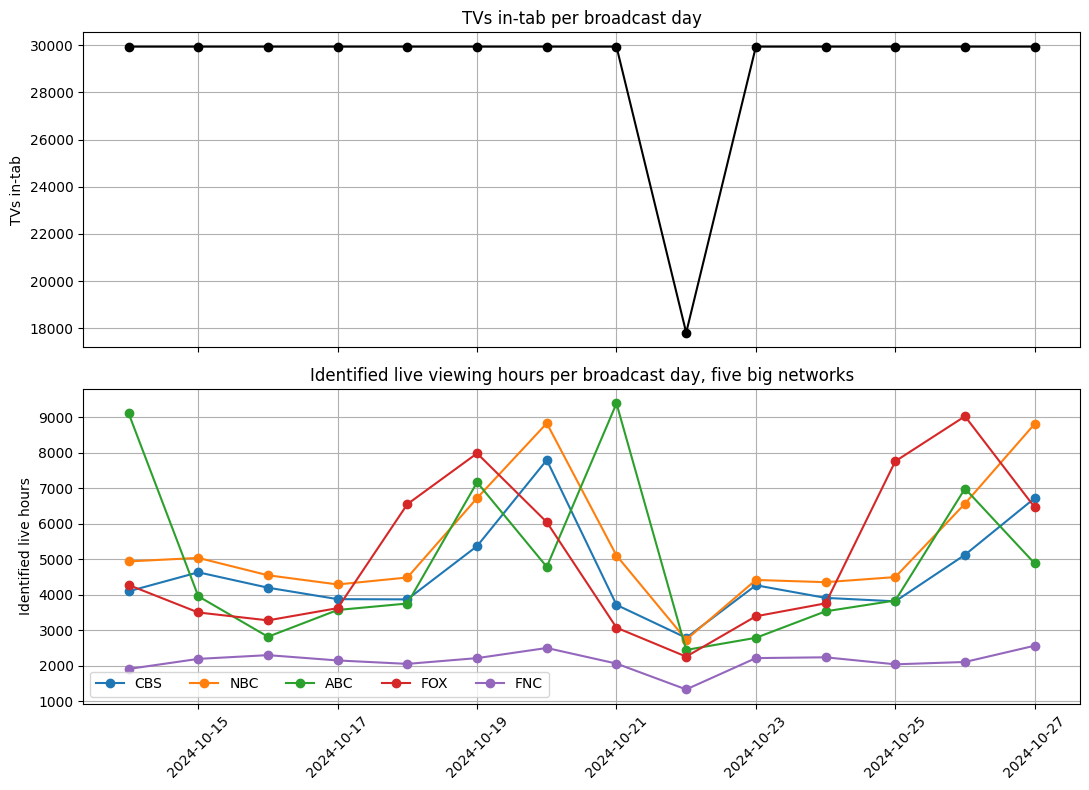

In [12]:
live_all = acr_ed[acr_ed['session_type'] == 'live']
daily_big = live_all[live_all['network_code'].isin(big5)].groupby(['bc_date', 'network_code'])['dur_min'].sum().unstack() / 60

fig, ax = plt.subplots(2, 1, figsize=(11, 8), sharex=True)

ax[0].plot(tv_days.index, tv_days.values, marker='o', color='black')
ax[0].set_ylabel("TVs in-tab")
ax[0].set_title("TVs in-tab per broadcast day")
ax[0].grid(True)

for net in big5:
    ax[1].plot(daily_big.index, daily_big[net], marker='o', label=net)
ax[1].set_ylabel("Identified live hours")
ax[1].set_title("Identified live viewing hours per broadcast day, five big networks")
ax[1].legend(ncol=5)
ax[1].grid(True)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## Task 4.2 — Spike and broken day

Top 5 network-days by identified live hours:
bc_date     network_code
2024-10-21  ABC             9392.46
2024-10-14  ABC             9117.65
2024-10-26  FOX             9030.21
2024-10-20  NBC             8833.79
2024-10-27  NBC             8815.71
Biggest spike (date, network): 2024-10-21, ABC


,start_ts,program_name,episode_name,genre,program_type,duration_min,is_live
282,2024-10-21 20:15:00,NFL Football,NFL Football: BAL @ TB,Sports,sports,190,True
272,2024-10-21 07:00:00,Good Morning America,"Alessia Cara, Jenny Slate, Dr. Jill Biden",Talk Show,talk,120,True
274,2024-10-21 11:00:00,The View,Tim Walz,Talk Show,talk,60,True
276,2024-10-21 13:00:00,GMA3,"Sec. Al Schmidt, Courtney Mason",Family,news,60,True
279,2024-10-21 18:30:00,ABC World News Tonight with David Muir,Episode 283,News,news,30,True
284,2024-10-22 00:35:00,Nightline,Episode 210,News,news,30,True
285,2024-10-22 01:05:00,Local / Syndicated Programming,NaN,General,local,355,False
278,2024-10-21 15:00:00,Local / Syndicated Programming,NaN,General,local,210,False
273,2024-10-21 09:00:00,Local / Syndicated Programming,NaN,General,local,120,False
283,2024-10-21 23:25:00,Local / Syndicated Programming,NaN,General,local,70,False


,tvs_intab,sessions,hours,dmas,dup_sessions,sessions_per_tv,hours_per_tv,unknown_share
bc_date,,,,,,,,
2024-10-14,29940,305581,135257.43,39,398,10.21,4.52,0.39
2024-10-15,29940,320019,133543.88,39,395,10.69,4.46,0.39
2024-10-16,29940,327113,133115.80,39,362,10.93,4.45,0.40
2024-10-17,29940,324975,131951.90,39,415,10.85,4.41,0.40
2024-10-18,29940,308311,131460.60,39,363,10.30,4.39,0.40
2024-10-19,29940,357221,158983.42,39,655,11.93,5.31,0.40
2024-10-20,29940,359443,159161.69,39,622,12.01,5.32,0.39
2024-10-21,29940,312370,136378.94,39,447,10.43,4.56,0.39
2024-10-22,17818,190991,79258.87,39,227,10.72,4.45,0.39


Broken day (date): 2024-10-22
Deviation from the median, broken day:
tvs_intab         -0.405
sessions_per_tv   -0.014
hours_per_tv      -0.001


,broken_day,other_days_avg
tvs_intab,17818.00,29940.00
sessions,190991.00,330036.15
hours,79258.87,141110.93
dmas,39.00,39.00
dup_sessions,227.00,481.08
sessions_per_tv,10.72,11.02
hours_per_tv,4.45,4.71
unknown_share,0.39,0.40


In-tab TVs by DMA on the broken day / normal day: min, median, max
0.56 0.59 0.63


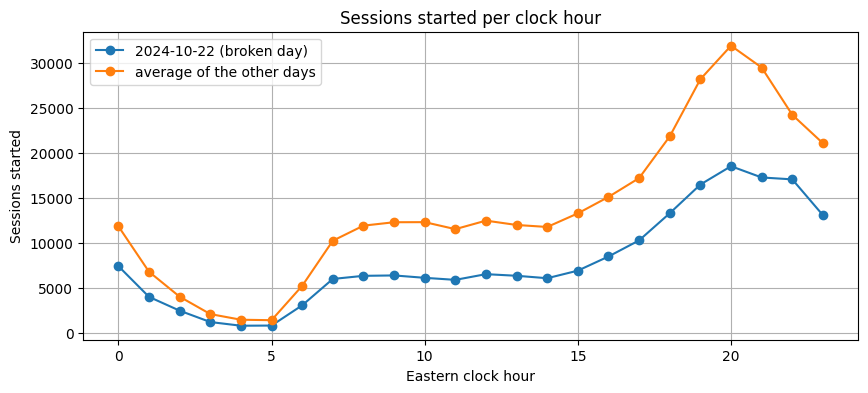

In [16]:
hours_nd = live_all.groupby(['bc_date', 'network_code'])['dur_min'].sum() / 60
print("Top 5 network-days by identified live hours:")
print(hours_nd.sort_values(ascending=False).head(5).round(2).to_string())

spike_day, spike_net = hours_nd.idxmax()
print("Biggest spike (date, network):", f"{spike_day.strftime('%Y-%m-%d')}, {spike_net}")

# what aired there
aired = prog[(prog['network_code'] == spike_net) & (prog['broadcast_date'] == spike_day)]
display(aired.sort_values(['is_live', 'duration_min'], ascending=False)[['start_ts', 'program_name', 'episode_name', 'genre', 'program_type', 'duration_min', 'is_live']].head(10))

# a broken day should show up in the denominator: TVs in-tab and hours per in-tab TV
acr_ed['dup'] = acr_ed.duplicated(['tv_id', 'start_utc', 'end_utc', 'network_code'])
g = acr_ed.groupby('bc_date')
daily = pd.DataFrame({'tvs_intab': tv_days,
                      'sessions': g.size(),
                      'hours': g['dur_min'].sum() / 60,
                      'dmas': g['dma_code'].nunique(),
                      'dup_sessions': g['dup'].sum()})
daily['sessions_per_tv'] = daily['sessions'] / daily['tvs_intab']
daily['hours_per_tv'] = daily['hours'] / daily['tvs_intab']
daily['unknown_share'] = acr_ed[acr_ed['session_type'] == 'unknown'].groupby('bc_date')['dur_min'].sum() / 60 / daily['hours']
display(daily.round(2))

# the day that is furthest from the median in in-tab TVs, sessions per TV or hours per TV
dev = daily[['tvs_intab', 'sessions_per_tv', 'hours_per_tv']] / daily[['tvs_intab', 'sessions_per_tv', 'hours_per_tv']].median() - 1
broken_day = dev.abs().max(axis=1).idxmax()
print("Broken day (date):", broken_day.strftime('%Y-%m-%d'))
print("Deviation from the median, broken day:")
print(dev.loc[broken_day].round(3).to_string())

# compare with the other days
cmp = pd.DataFrame({'broken_day': daily.loc[broken_day], 'other_days_avg': daily.drop(broken_day).mean()})
display(cmp.round(2))

# were some markets lost?
dma_day = acr_ed.groupby(['bc_date', 'dma_code'])['tv_id'].nunique().unstack(fill_value=0)
dma_ratio = (dma_day.loc[broken_day] / dma_day.drop(broken_day).mean()).replace([np.inf, -np.inf], np.nan).dropna().sort_values()
print("In-tab TVs by DMA on the broken day / normal day: min, median, max")
print(round(float(dma_ratio.min()), 2), round(float(dma_ratio.median()), 2), round(float(dma_ratio.max()), 2))

# when during the day? sessions started per clock hour
hour_prof = acr_ed.groupby(['bc_date', acr_ed['start_et'].dt.hour]).size().unstack(fill_value=0)
plt.figure(figsize=(10, 4))
plt.plot(hour_prof.columns, hour_prof.loc[broken_day].values, marker='o', label=f"{broken_day.strftime('%Y-%m-%d')} (broken day)")
plt.plot(hour_prof.columns, hour_prof.drop(broken_day).mean().values, marker='o', label="average of the other days")
plt.xlabel("Eastern clock hour")
plt.ylabel("Sessions started")
plt.title("Sessions started per clock hour")
plt.legend()
plt.grid(True)
plt.show()

**Answer:** The biggest spike is ABC on 2024-10-21, with 9,392 identified live hours. That day ABC aired Monday Night Football (NFL Football: BAL @ TB, 190 minutes live from 20:15) on top of its normal live programs. The previous Monday, 2024-10-14, is also very high for ABC (9,118 hours), which fits the same reason. The other peaks in the plot are NFL Sundays on NBC and the World Series on FOX (FOX on 2024-10-26 has 9,030 hours).

The broken day is 2024-10-22. TVs in-tab fall from 29,940 to 17,818 (-40%), but sessions per TV (10.7) and hours per TV (4.45) are normal. All 39 DMAs are still there, and each lost a similar share of TVs (0.56 to 0.63 of a normal day). The sessions per clock hour have the same shape as on other days, only lower at every hour. Every TV is in-tab on all other days, so this is not the audience: about 40% of the TVs did not send data that day. If nobody noticed, the daily totals (hours, projected audience) would look like viewing fell by 40%, and all big networks drop on that day in the plot. A rating would stay about the same if the missing TVs are random, because we divide by the TVs in-tab that day. But it would rest on 40% fewer TVs, so it is less precise. If someone divided by all 29,940 TVs by mistake, the rating would fall by about 40%. We also cannot check if the missing TVs are different. I would flag the day. I would not fix it, because scaling it up would invent what the missing TVs watched. I would not drop it, because the rest of its data is still good. I would keep the rows, add a note to the day, and not compare its daily totals with other days. Per-TV numbers and ratings from that day can be used with the note.

## Task 5.1 — Sampling error vs bias

In [14]:
# Sunday Night Football (NBC), Hannity (FNC) and Unsellable Houses (HGTV): one telecast per network in the reference list
pick = ratings_tbl[ratings_tbl['network'].isin(['NBC', 'FNC', 'HGTV'])]
pick = pick.merge(ref[['telecast_id', 'broadcast_date', 'hh_rating']], on='telecast_id')

# panel households (H) in-tab that day
n_panel_day = dw[dw['resp_type'] == 'H'].groupby('broadcast_date')['respondent_id'].nunique()

rows = []
for _, t in pick.iterrows():
    p = t['ref_rating'] / 100
    n_tv = tv_days[t['broadcast_date']]
    n_pan = n_panel_day[t['broadcast_date']]
    rows.append({'telecast': t['telecast'],
                 'n_tvs': n_tv,
                 'n_panel_hh': n_pan,
                 'se_footprint': np.sqrt(p * (1 - p) / n_tv) * 100,
                 'se_panel': np.sqrt(p * (1 - p) / n_pan) * 100,
                 'tv_minus_ref': t['tv_rating'] - t['ref_rating']})

se_tbl = pd.DataFrame(rows)
se_tbl['panel_se_over_footprint_se'] = se_tbl['se_panel'] / se_tbl['se_footprint']
se_tbl['bias_over_se_footprint'] = se_tbl['tv_minus_ref'].abs() / se_tbl['se_footprint']

# table: telecast, SE footprint, SE panel, TVs' rating - reference (in rating points)
display(se_tbl.round(3))

,telecast,n_tvs,n_panel_hh,se_footprint,se_panel,tv_minus_ref,panel_se_over_footprint_se,bias_over_se_footprint
0,NFL Football,29940,3898,0.272,0.754,-11.891,2.771,43.710
1,Hannity,29940,3867,0.087,0.241,-1.475,2.783,17.026
2,Unsellable Houses,29940,3867,0.109,0.303,-1.592,2.783,14.617


**Answer:** The sampling error of the footprint is about 2.8 times smaller than the panel's: 0.27, 0.09 and 0.11 rating points for Sunday Night Football, Hannity and Unsellable Houses, against 0.75, 0.24 and 0.30 for the panel (29,940 TVs against about 3,900 households). But the gap between the TVs' rating and the reference is -11.9, -1.5 and -1.6 points. This is 44, 17 and 15 times the footprint's standard error. So the bias is the bigger error. More data does not fix it. The standard error gets smaller when n grows (it goes down with the square root of n). But the bias comes from who and what is missing (other sets, unknown viewing, homes that did not opt in). Adding more TVs of the same kind leaves the bias the same.

## Task 5.2 — Answer to the planner
**Answer:** Today I can give 21.2 as the unweighted household rating of Sunday Night Football in the smart-TV footprint (29,940 TVs), only with the label "smart-TV footprint, not US". I would not call it the US rating: in this lab the reference is 33.1, so the feed is 11.9 points (36%) too low, and all eight telecasts we checked are too low. The feed cannot see people (only that a TV is tuned), other sets in the home, apps, unknown viewing (39.6% of the hours) or homes that did not opt in. Also, 35% of its TVs could not be matched to one household, so we know little about who lives there (this limits the profile, not the rating). Its sampling error is small (0.27 points), so the problem is bias, not the number of TVs. Before using it for planning I would need weights to project the TVs to US households (Lab 4), a check against the panel or currency, and a source for people, such as A25-54; I would also check data quality, because the feed lost 40% of its TVs on 2024-10-22.For tomorrow's presentation I would use the panel or currency number, and I would not use the feed even to compare programs with each other, because the bias is not the same for all of them (Hannity gets only 0.36 of its reference rating and NCIS 0.51, against 0.64 for Sunday Night Football), so older-skewing programs look weaker than they are.

## Bonus

In [15]:
# Sunday Night Football, NBC, Oct 27
t = ref[ref['network_code'] == 'NBC'].iloc[0]
day = t['broadcast_date']
w_day = dw[dw['broadcast_date'] == day].set_index('respondent_id')

# A25-54: exact age (code 300), persons only
age = viewer_attributes[viewer_attributes['attr_id'] == 300].drop_duplicates('respondent_id').set_index('respondent_id')['value']
a25_54 = set(age[(age >= 25) & (age <= 54)].index)
print("Persons with an exact age (%):", round(age.index.isin(w_day.index).sum() / (w_day['resp_type'] != 'H').sum() * 100, 1))

# who watched at least 1 minute of the telecast (Lab 1 rule)
vv = v[v['network_code'] == t['network_code']]
overlap = (vv['end_ts'].clip(upper=t['end_ts']) - vv['start_ts'].clip(lower=t['start_ts'])).dt.total_seconds() / 60
vv = vv[overlap >= 1]
hh_watch = vv.loc[vv['resp_type'] == 'H', 'respondent_id'].unique()
p_watch = [r for r in vv.loc[vv['resp_type'].isin(['R', 'L']), 'respondent_id'].unique() if r in a25_54]

w = w_day['weight']
vpvh = w.reindex(p_watch).sum() / w.reindex(hh_watch).sum()

# universes from that day's panel weights
us_hh = w[w_day['resp_type'] == 'H'].sum()
us_a25_54 = w[w_day.index.isin(a25_54) & (w_day['resp_type'] != 'H')].sum()

tv_hh_rating = ratings_tbl.loc[ratings_tbl['telecast_id'] == t['telecast_id'], 'tv_rating'].iloc[0]
a25_54_rating = tv_hh_rating * vpvh * us_hh / us_a25_54

print(f"VPVH A25-54: {vpvh:.2f}")
print(f"A25-54 rating (persons): {a25_54_rating:.1f}")

Persons with an exact age (%): 100.0
VPVH A25-54: 0.51
A25-54 rating (persons): 11.1


**Answer:** VPVH is 0.51 A25-54 persons per viewing household, and the A25-54 rating for Sunday Night Football is 11.1. This assumes that the footprint's homes are like the panel's homes that watched the game: the same number of A25-54 persons per viewing home (same household size and age mix). It also assumes that the ratio of households to A25-54 persons in the panel is the same as in the US. And it assumes that the TVs' household rating is right, but it is 21.2 against 33.1 in the reference, so the 11.1 is too low by the same share. Also, the footprint has more higher-income homes than the panel, and their VPVH may be different.